**← Previous:** [Model Diagnostics](08_model_diagnostics.ipynb)  
**→ Next:** [Report](10_report.ipynb)

```text
Policy
├── Import & Setup
├── Define policies
├── Quantify impact
└── Policy Optimisation
```

#### Import & Setup 

In [1]:
# Init work dir

from pathlib import Path
import sys
PROJECT_ROOT = Path.cwd().parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

In [2]:
# Standard modules

import pandas as pd

# Framework

from credit_risk_framework.decisioning import policy_create_grid, policy_create_pareto
from credit_risk_framework.feature_engineering import create_target_def12
from credit_risk_framework.metrics import calculate_metrics
from credit_risk_framework.modelling import apply_pipe_PD, apply_pipe_LGD, estimate_capital
from credit_risk_framework.plots import plot_pareto
from credit_risk_framework.preprocessing import input_load
from credit_risk_framework.utils import format_policy_table

# Dataset specific settings

from credit_risk_framework import settings_dataset_unsecured as settings

# Configuration

pd.set_option("display.max_columns", None)
pd.set_option("display.width", None)
pd.set_option("display.expand_frame_repr", False)
from sklearn import set_config; set_config(transform_output="pandas")

In [3]:
# load input file

portfolio = input_load(2021, 2021, column_date=settings.COLUMN_DATE, column_year=settings.COLUMN_YEAR)
portfolio, dr_summary = create_target_def12(portfolio, 
                                            settings.COLUMN_DATE,
                                            settings.COLUMN_YEAR, 
                                            settings.COLUMN_TARGET_DATE,
                                            settings.COLUMN_TARGET, 
                                            verbose=False,
                                            )

In [4]:
# load PD, LGD pipelines

import joblib
pipeline_pd  = joblib.load("../models/PIPELINE_PD_v014_LR_cal_shift-test.pkl")
pipeline_lgd = joblib.load("../models/PIPELINE_LGD_v014_stochastic.pkl")

# estimate PD, LGD

portfolio = apply_pipe_PD(portfolio, pipeline_pd)
portfolio = apply_pipe_LGD(portfolio, pipeline_lgd)

/Users/konstantinoskazanas/Downloads/DATA SCIENCE/MLenv/lib/python3.11/site-packages/sklearn/preprocessing/_encoders.py:261: UserWarning: Found unknown categories in columns [4] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)


## Define Policies

In [5]:
# no policy

policy_0 = portfolio

# Policy 1: PD based (PD < 0.20)

policy_1 = portfolio[portfolio["PD"]<0.20]

# Policy 2: Exposure based (Amount < 7.5k)

policy_2 = portfolio[portfolio[settings.COLUMN_EAD]<7500]

# Policy 3: Combined (PD < 0.20 and Amount < 7.5k)

policy_3 = portfolio[(portfolio["PD"]<0.20) & (portfolio[settings.COLUMN_EAD]<7500)]

# Policies

policies = {"NO POLICY": policy_0, "POLICY[PD based]": policy_1, "POLICY[exposure based]": policy_2, "POLICY[combined]": policy_3,}

## Quantify Impact

In [6]:
# impact: metrics + capital

policy_metrics = {}

for name, policy in policies.items():

    metrics = calculate_metrics(policy[settings.COLUMN_TARGET], policy["PD"], exposure=policy[settings.COLUMN_EAD], dataset_name=name, verbose=False)

    _, loss_summary, el_summary, _ = estimate_capital(policy, 
                                                      method="monte-carlo", 
                                                      column_lgd="LGD",
                                                      column_def=settings.COLUMN_TARGET,
                                                      column_ead=settings.COLUMN_EAD,
                                                      )
    el = el_summary["EL (MC-simulated)"]
    ec = loss_summary["Economic Capital"]

    policy_metrics[name] = {
        **metrics,
        "Expected Loss (Monte-Carlo)"   : el_summary["EL (MC-simulated)"],
        "Economic Capital (Monte-Carlo)": loss_summary["Economic Capital"]
    }

# table

policy_table = pd.DataFrame(policy_metrics)
display(format_policy_table(policy_table))

# CHECK KEY RESULT: output must be as follows (use this as a reference to check your results)
# Dataset	              NO POLICY	
# AUC	                      0.681	
# KS	                      0.260	
# Observed_DR	             12.21%	
# Mean_PD	                 15.64%	
# Brier	                      0.103	
# Exposure	             85,557,401	
# Expected Loss (M-C)	  2,472,247 (when LGD model is stochastic)
# Economic Capital (M-C)	219,165 (when LGD model is stochastic)
# Expected Loss (M-C)	  2,117,683 (when LGD model is univariate)
# Economic Capital (M-C)	117,014 (when LGD model is univariate)


,NO POLICY,POLICY[PD based],POLICY[exposure based],POLICY[combined]
Dataset,NO POLICY,POLICY[PD based],POLICY[exposure based],POLICY[combined]
AUC,0.681,0.636,0.680,0.636
KS,0.260,0.201,0.259,0.204
Observed_DR,12.21%,9.21%,11.92%,9.17%
Mean_PD,15.64%,12.48%,15.30%,12.38%
Brier,0.103,0.083,0.101,0.083
Exposure,"85,557,401","59,068,472","66,052,220","47,892,899"
Expected Loss (Monte-Carlo),"2,467,571","1,278,999","1,826,935","1,011,992"
Economic Capital (Monte-Carlo),"236,400","174,227","178,971","129,513"


## Policy Optimisation

In [7]:
# PD thresholds
pd_thresholds = [
    0.10, 0.125, 0.15, 0.175, 0.20,
    0.225, 0.25, 0.275, 0.30, 0.325,
    0.35, 0.375, 0.40
]

# EAD thresholds
ead_thresholds = list(range(2500, 15001, 500))

# create PD x EAD grid
policy_grid = policy_create_grid(
    portfolio,
    pd_thresholds,
    ead_thresholds,
    "PD",
    settings.COLUMN_EAD,
    "LGD",
    settings.COLUMN_TARGET,
    show_table=False)

Number of policies evaluated: 338


In [14]:
# create Pareto frontier
pareto_frontier = policy_create_pareto(policy_grid, column_approval="Approval_rate", column_loss="Expected_Loss", show_table=False)

In [15]:
# select the pareto policies that are improved (larger approval and smaller loss)
# as compared to the benchmark policy

existing_policy = policy_grid[(policy_grid["PD_max"] == 0.20) & (policy_grid["EAD_max"] == 7500)]
existing_approval = existing_policy["Approval_rate"].iloc[0]
existing_loss     = existing_policy["Expected_Loss"].iloc[0]
print('existing_approval: ', existing_approval)
print('existing_loss    : ', existing_loss)
improved_policies = pareto_frontier[(pareto_frontier["Approval_rate"] > existing_approval)
                                  & (pareto_frontier["Expected_Loss"] < existing_loss)].copy()
display(improved_policies)

# select 3 policies
selected_policies = improved_policies.loc[[49,56,59]]
display(selected_policies)

existing_approval:  0.7451265446375471
existing_loss    :  1012065.9324428578


,PD_max,EAD_max,Approved_count,Approval_rate,Exposure,Exposure_share,Observed_DR,Mean_PD,Expected_Loss,EL_to_Exposure
49,0.300,4500,22764,0.752131,3.550254e+07,0.414956,0.103541,0.137726,820131.515104,0.023101
50,0.275,5000,22790,0.752990,3.678157e+07,0.429905,0.100834,0.135060,829459.003576,0.022551
51,0.325,4500,23061,0.761944,3.608153e+07,0.421723,0.105763,0.139972,852257.808042,0.023620
52,0.300,5000,23224,0.767330,3.769701e+07,0.440605,0.103427,0.137895,869276.773684,0.023060
53,0.350,4500,23284,0.769312,3.651649e+07,0.426807,0.107198,0.141852,872524.214637,0.023894
54,0.375,4500,23410,0.773475,3.679075e+07,0.430012,0.107903,0.143031,886425.232302,0.024094
55,0.400,4500,23519,0.777077,3.702322e+07,0.432730,0.108678,0.144160,900473.964168,0.024322
56,0.325,5000,23532,0.777506,3.832790e+07,0.447979,0.105686,0.140176,905408.550088,0.023623
57,0.350,5000,23764,0.785171,3.880506e+07,0.453556,0.107137,0.142090,929045.006670,0.023941
58,0.375,5000,23897,0.789566,3.911270e+07,0.457152,0.107838,0.143307,946308.258954,0.024194


,PD_max,EAD_max,Approved_count,Approval_rate,Exposure,Exposure_share,Observed_DR,Mean_PD,Expected_Loss,EL_to_Exposure
49,0.300,4500,22764,0.752131,3.550254e+07,0.414956,0.103541,0.137726,820131.515104,0.023101
56,0.325,5000,23532,0.777506,3.832790e+07,0.447979,0.105686,0.140176,905408.550088,0.023623
59,0.400,5000,24009,0.793266,3.935953e+07,0.460037,0.108626,0.144443,961392.619160,0.024426


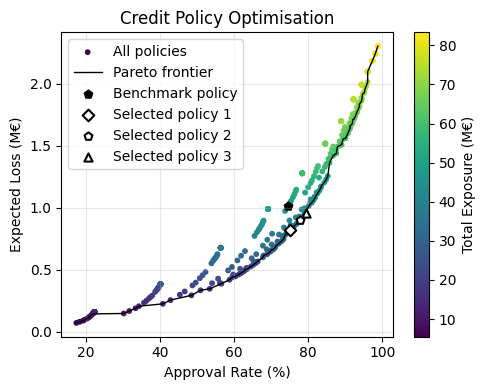

In [16]:
# plot
plot_pareto(
    policy_grid,
    pareto_frontier,
    benchmark_policy=[0.20,7500],
    selected_policies=[[0.30, 4500],[0.325, 5000],[0.4, 5000]],
)